
This is our sandbox for the assignment, any cell that we decide to become permanent for the assigment should be copied and moved to the ProjectSubmission.ipynb (name can be changed later if needed)</br>
Since we need to replace Logistic Regression (from the proposal) with a stronger baseline and ensure we meet the good experimental design criteria, I will structure the notebook to include:

- Data Loading & Exploration
- Preprocessing & Label Consolidation
- Baseline Model: A Frequency-Based/Keyword Heuristic
- Advanced Models: Linear SVM and Random Forest
- Evaluation: K-Fold Cross-Validation, Confusion Matrices, and detailed Error Analysis

to begin, i started to make sure our datasets were working, there were a lot of issues getting the original dataset to work because it was removed for outdated python code within so I found a new source that provides much of what we need.


## Step 1 : Setup and Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.pipeline import Pipeline

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

## Import dataset and extract emotion labels

In [2]:
from datasets import load_dataset

dataset = load_dataset("dair-ai/emotion")
df = dataset['train'].to_pandas()

# Check the label column directly
print("Label values:", df['label'].unique())
print("\nLabel distribution:")
print(df['label'].value_counts().sort_index())

# Check the dataset card for the official mapping
print("\nDataset info:")
print(dataset['train'].features)


/s/chopin/n/under/C837364858/Ambers_Work/CS-SPRING-2026/.conda/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Label values: [0 3 2 5 4 1]

Label distribution:
label
0    4666
1    5362
2    1304
3    2159
4    1937
5     572
Name: count, dtype: int64

Dataset info:
{'text': Value('string'), 'label': ClassLabel(names=['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'])}


## Show Mapping

In [3]:
# emotion mapping (verified from dataset)
emotion_map = {
    0: 'sadness',
    1: 'joy',
    2: 'love',
    3: 'anger',
    4: 'fear',
    5: 'surprise'
}

df['emotion_name'] = df['label'].map(emotion_map)

print("emotion mapping applied")
print("\nOriginal emotion distribution:")
print(df['emotion_name'].value_counts())

emotion mapping applied

Original emotion distribution:
emotion_name
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64


## consolidation for gen guardian

In [4]:
# Consolidate into 6 Gen Guardian categories
consolidation_map = {
    'anger': 'anger/frustration',
    'fear': 'exhaustion/overwhelm',  # Fear → overwhelm
    'joy': 'calm/in-control',
    'love': 'calm/in-control',
    'sadness': 'sadness/disappointment',
    'surprise': 'confusion/uncertainty'  # Surprise → uncertainty
}

df['consolidated_emotion'] = df['emotion_name'].map(consolidation_map)



/tmp/ipykernel_2485127/4077311477.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


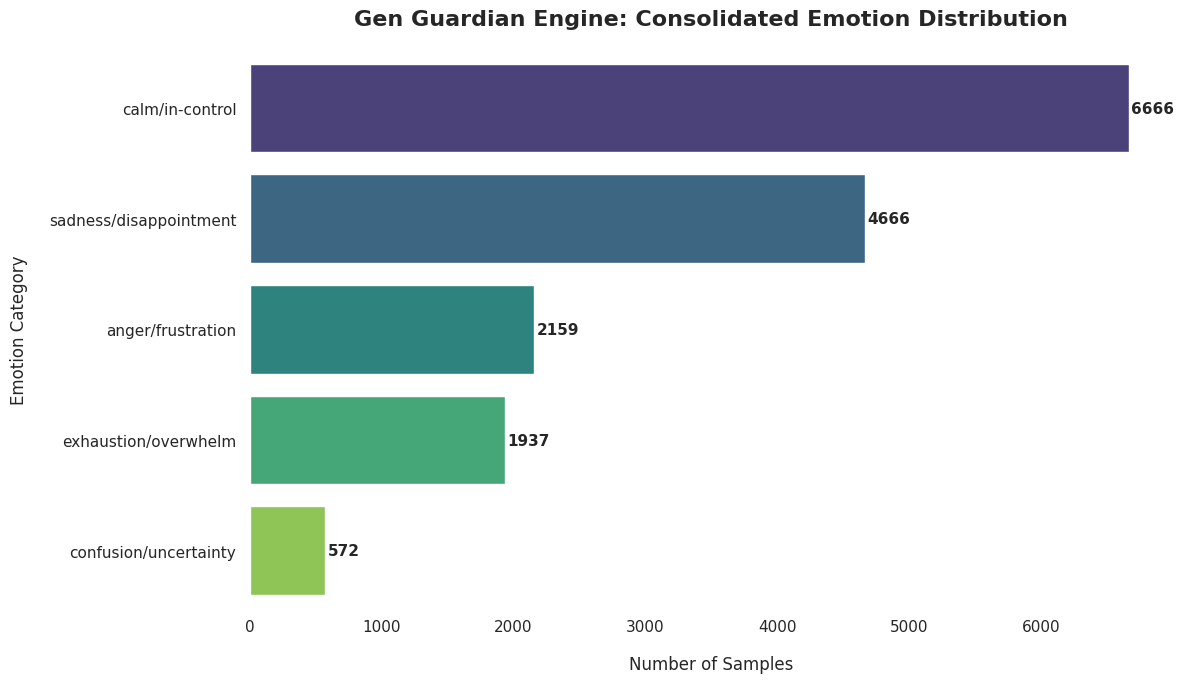

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean, minimalist theme
sns.set_theme(style="white")

plt.figure(figsize=(12, 7))


ax = sns.countplot(
    data=df, 
    y='consolidated_emotion', 
    order=df['consolidated_emotion'].value_counts().index,
    palette='viridis' 
)

plt.title('Gen Guardian Engine: Consolidated Emotion Distribution', fontsize=16, pad=20, fontweight='bold')
plt.xlabel('Number of Samples', fontsize=12, labelpad=15)
plt.ylabel('Emotion Category', fontsize=12, labelpad=15)

# Add exact count labels for your report's data analysis section
for p in ax.patches:
    width = p.get_width()
    plt.text(
        width + 20, 
        p.get_y() + p.get_height() / 2, 
        f'{int(width)}', 
        ha='left', 
        va='center',
        fontsize=11,
        fontweight='bold'
    )

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

In [7]:
from sklearn.model_selection import train_test_split

# Split data (Stratified to ensure balanced classes in train/test)
X = df['cleaned_text']
y = df['consolidated_emotion']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(f"Training set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")

# --- BASELINE: Keyword Matching Heuristic ---
#  scores based on keyword density.
def keyword_baseline_predict(text):
    text_lower = text.lower()
    scores = {
        'anger/frustration': len(re.findall(r'angry|mad|furious|hate|annoyed|stupid|idiot', text_lower)),
        'exhaustion/overwhelm': len(re.findall(r'tired|exhausted|overwhelmed|scared|fear|panic|stress', text_lower)),
        'calm/in-control': len(re.findall(r'good|happy|love|great|wonderful|peaceful|calm|relaxed', text_lower)),
        'sadness/disappointment': len(re.findall(r'sad|cry|tears|disappointed|hopeless|lonely|miss', text_lower)),
        'confusion/uncertainty': len(re.findall(r'confused|dont know|uncertain|surprised|wonder|maybe|why', text_lower)),
    }
    
    max_score = max(scores.values())
    if max_score == 0:
        return 'calm/in-control'  # Default fallback
    
    # Return the category with the highest score
    return [k for k, v in scores.items() if v == max_score][0]

# Evaluate Baseline
baseline_preds = [keyword_baseline_predict(t) for t in X_test]
baseline_acc = accuracy_score(y_test, baseline_preds)
baseline_f1 = f1_score(y_test, baseline_preds, average='weighted')

print(f"\n📊 Baseline Results:")
print(f"Accuracy: {baseline_acc:.4f}")
print(f"Weighted F1-Score: {baseline_f1:.4f}")

KeyError: 'cleaned_text'

In [11]:
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

# 1. SVM Model
print("Training Linear SVM...")
svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words='english')),
    ('svm', LinearSVC(random_state=42, max_iter=5000))
])
svm_pipeline.fit(X_train, y_train)
svm_preds = svm_pipeline.predict(X_test)

# 2. Random Forest Model
print("Training Random Forest...")
rf_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words='english')),
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])
rf_pipeline.fit(X_train, y_train)
rf_preds = rf_pipeline.predict(X_test)

# Evaluate Models
print("MODEL COMPARISON RESULTS")


models = {
    "Baseline (Keywords)": (baseline_preds, baseline_acc, baseline_f1),
    "Linear SVM": (svm_preds, accuracy_score(y_test, svm_preds), f1_score(y_test, svm_preds, average='weighted')),
    "Random Forest": (rf_preds, accuracy_score(y_test, rf_preds), f1_score(y_test, rf_preds, average='weighted'))
}

results_df = pd.DataFrame([
    {"Model": name, "Accuracy": acc, "Weighted F1": f1}
    for name, (_, acc, f1) in models.items()
])

print(results_df.to_string(index=False))

Training Linear SVM...
Training Random Forest...
MODEL COMPARISON RESULTS
              Model  Accuracy  Weighted F1
Baseline (Keywords)  0.440763     0.346584
         Linear SVM  0.921687     0.920795
      Random Forest  0.904284     0.903827



🔍 Detailed Classification Report (SVM):
                        precision    recall  f1-score   support

     anger/frustration       0.92      0.89      0.90       406
       calm/in-control       0.93      0.97      0.95      1227
 confusion/uncertainty       0.78      0.67      0.72       108
  exhaustion/overwhelm       0.88      0.86      0.87       361
sadness/disappointment       0.94      0.93      0.93       886

              accuracy                           0.92      2988
             macro avg       0.89      0.86      0.87      2988
          weighted avg       0.92      0.92      0.92      2988



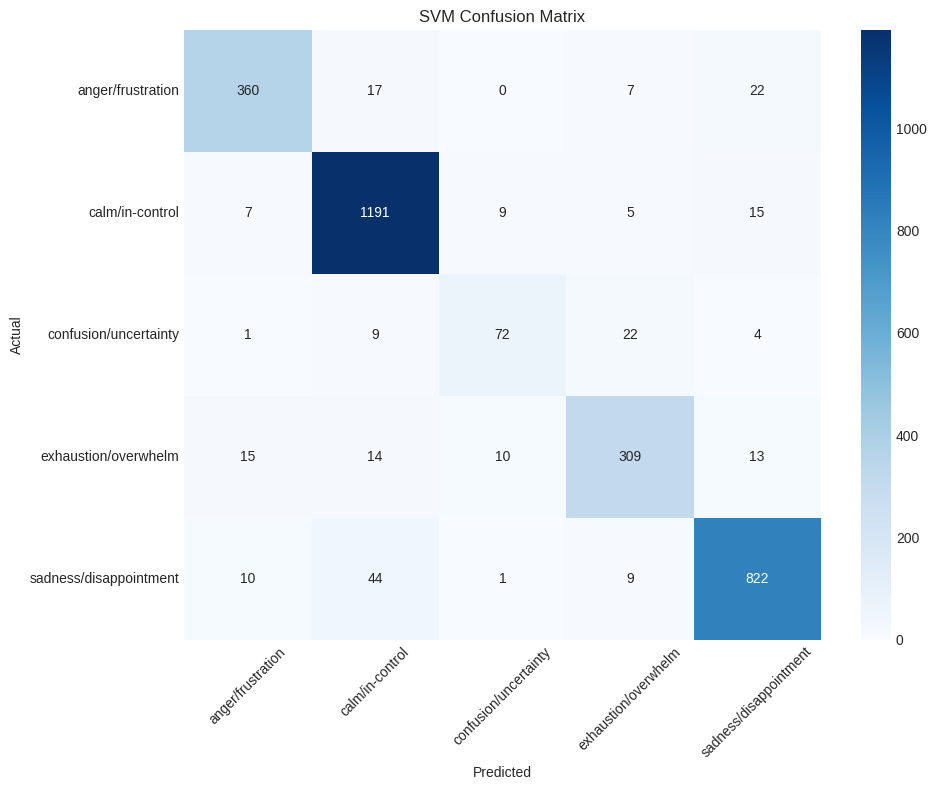


🚨 Found 234 misclassified samples.

Sample Errors (Actual vs Predicted):
Index: 4719
Actual: calm/in-control | Predicted: sadness/disappointment
Text: 'i think the most significant feeling that i am left with after being here for a week is that we are all deeply privileged to live where we live and have what we have'

Index: 10848
Actual: calm/in-control | Predicted: exhaustion/overwhelm
Text: 'i find that in times where i feel i am not being respected or i am not getting the point across of how something may make me feel uncomfortable that being nice only seems to encourage these things to keep happening'

Index: 2363
Actual: sadness/disappointment | Predicted: calm/in-control
Text: 'i feel empty when i dont have something to care for'

Index: 11106
Actual: exhaustion/overwhelm | Predicted: anger/frustration
Text: 'i cant help feeling agitated about'

Index: 7839
Actual: anger/frustration | Predicted: sadness/disappointment
Text: 'the patient whom i expected to get well suddenly pass

In [ ]:
# Detailed Report for SVM
print("\n🔍 Detailed Classification Report (SVM):")
print(classification_report(y_test, svm_preds))

# Confusion Matrix for SVM
plt.figure(figsize=(10, 8))


# Get the sorted list of categories for consistent ordering
categories = sorted(df['consolidated_emotion'].unique())
cm_svm = confusion_matrix(y_test, svm_preds, labels=categories)
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=categories,
            yticklabels=categories)
plt.title('SVM Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- ERROR ANALYSIS FIX ---
# Create a DataFrame that aligns indices correctly
error_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': svm_preds,
    'Text': X_test  # This preserves the original index from the split
})

# Filter for errors
errors = error_df[error_df['Actual'] != error_df['Predicted']]

print(f"\n🚨 Found {len(errors)} misclassified samples.")
print("\nSample Errors (Actual vs Predicted):")

# Show first 5 errors
for idx, row in errors.head(5).iterrows():
    # Use .loc with the actual index 'idx'
    print(f"Index: {idx}")
    print(f"Actual: {row['Actual']} | Predicted: {row['Predicted']}")
    print(f"Text: '{row['Text']}'\n")

In [19]:
from sklearn.model_selection import GridSearchCV

# We use the same TF-IDF settings you already established in your draft
rf_tuning_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words='english')),
    ('rf', RandomForestClassifier(random_state=42, n_jobs=-1))
])

# Tuning n_estimators (number of trees) to satisfy the 'in-depth' requirement
param_grid_rf = {
    'rf__n_estimators': [50, 100, 200],
    'rf__max_depth': [None, 20],
}

print("Running Grid Search for Random Forest...")
grid_rf = GridSearchCV(rf_tuning_pipeline, param_grid_rf, cv=5, scoring='accuracy')
grid_rf.fit(X_train, y_train)

# Update your results with the best tuned model
best_rf_model = grid_rf.best_estimator_
rf_tuned_preds = best_rf_model.predict(X_test)

# Update the results dictionary/dataframe
results_df.loc[results_df['Model'] == 'Random Forest', 'Accuracy'] = accuracy_score(y_test, rf_tuned_preds)
results_df.loc[results_df['Model'] == 'Random Forest', 'Weighted F1'] = f1_score(y_test, rf_tuned_preds, average='weighted')

print(f"✅ Best RF Parameters: {grid_rf.best_params_}")

Running Grid Search for Random Forest...
✅ Best RF Parameters: {'rf__max_depth': None, 'rf__n_estimators': 200}


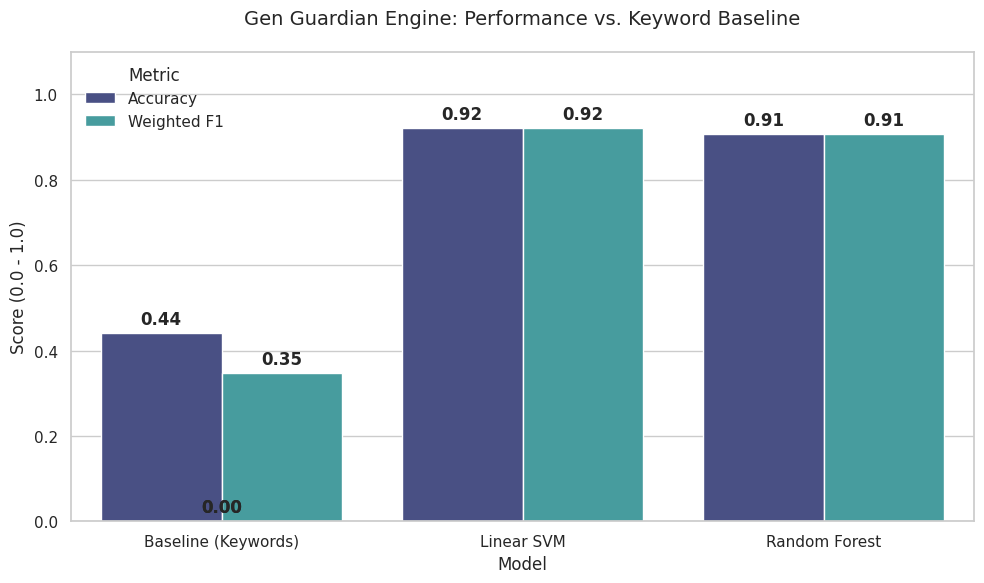

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

# Professional, colorblind-friendly palette
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Melt results for plotting
df_plot = results_df.melt(id_vars='Model', var_name='Metric', value_name='Score')

# Generate the plot
ax = sns.barplot(data=df_plot, x='Model', y='Score', hue='Metric', palette='mako')

plt.title('Gen Guardian Engine: Performance vs. Keyword Baseline', fontsize=14, pad=20)
plt.ylabel('Score (0.0 - 1.0)', fontsize=12)
plt.ylim(0, 1.1) 
plt.legend(title='Metric', loc='upper left')

# Add values on top of bars
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.2f'), 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 10), 
                textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()